# 01 — Profile the L&T train.csv

Calls `src/profiling.py`, which writes `reports/profile.md`. Real L&T data, no simulation.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())
import matplotlib.pyplot as plt
from src import profiling
p = profiling.main()
print(f"rows {p['rows']:,}  cols {p['cols']}  default rate {p['default_rate']:.1%}")

C:\Users\Shreyash\Downloads\BFSI PROJECT\src\profiling.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = df.groupby(by, dropna=False)[TARGET].agg(rows="size", default_rate="mean")


rows 233,154  cols 41  default rate 21.7%


In [2]:
display(p['by_month']); display(p['no_score']); display(p['employment'])

,rows,share,default_rate
month,,,
2018-08,68002,0.291661,0.215670
2018-09,66788,0.286454,0.191876
2018-10,98364,0.421884,0.235147


,rows,share,default_rate
group,,,
score == 0,116950,0.5016,0.231313
score > 0,116204,0.4984,0.202738


,rows,share,default_rate
Employment.Type,,,
Self employed,127635,0.547428,0.227657
Salaried,97858,0.419714,0.203458
Unknown,7661,0.032858,0.214593


In [3]:
display(p['score_desc'])
for c in profiling.contradictions(p):
    print('-', c)

,rows,default_rate,score_min,score_max
PERFORM_CNS.SCORE.DESCRIPTION,,,,
No Bureau History Available,116950,0.231313,0,0
C-Very Low Risk,16045,0.172639,736,760
A-Very Low Risk,14124,0.165746,806,890
D-Very Low Risk,11358,0.149586,706,735
B-Very Low Risk,9201,0.131290,761,805
M-Very High Risk,8776,0.304581,300,300
F-Low Risk,8485,0.186211,651,680
K-High Risk,8277,0.278120,351,520
H-Medium Risk,6855,0.241867,601,630


- 12,835 rows have a 'Not Scored'/'No Bureau' description but a non-zero PERFORM_CNS.SCORE (values 11–18). CLAUDE.md treats only score == 0 as no score; these rows would count as 'scored' under that rule. Decision needed before features.
- October default rate is 23.5% vs 20.4% in Aug–Sep: a base-rate shift in the out-of-time month. Probabilities calibrated on Aug–Sep will under-predict October; check calibration-in-the-large in step 4.
- test.csv is disbursed 03 Nov – 30 Nov 2018, after train.csv, not Aug–Oct as the guide says. It has no label, so this changes nothing for evaluation, but it is a later-period sample usable for score-drift (PSI) checks.


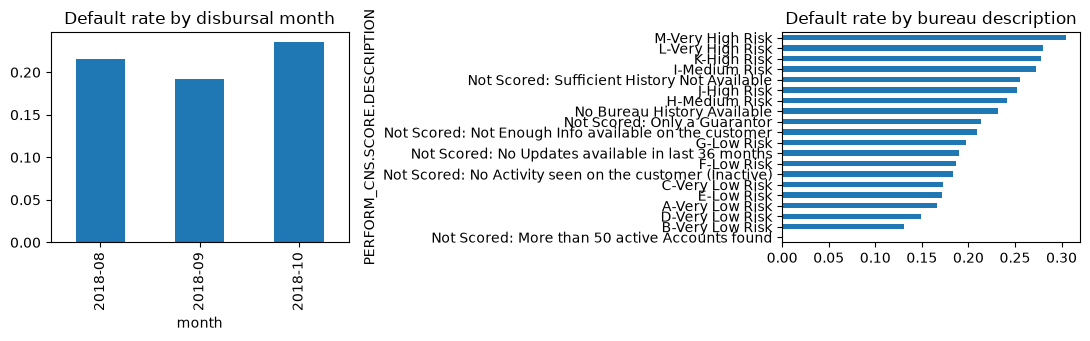

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
p['by_month']['default_rate'].plot.bar(ax=ax[0], title='Default rate by disbursal month')
p['score_desc']['default_rate'].sort_values().plot.barh(ax=ax[1], title='Default rate by bureau description')
plt.tight_layout(); os.makedirs('reports/figures', exist_ok=True)
fig.savefig('reports/figures/01_profile.png', dpi=120)